---
title: "Chapter 2: Equations and Inequalities"
subtitle: Notes drawn from OpenStax *Algebra and Trigonometry 2e* (§2.1–2.7) and *Precalculus 2e*
---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})
# colorblind-safe palette (Okabe-Ito)
C = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73",
     "red": "#D55E00", "purple": "#CC79A7", "sky": "#56B4E9", "gray": "#666666"}

def axes_through_origin(ax, xlim, ylim, grid=True):
    """Draw x/y axes through (0, 0) with a light grid, like the textbook figures."""
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.axhline(0, color="black", lw=0.8); ax.axvline(0, color="black", lw=0.8)
    if grid:
        ax.grid(True, color="#dddddd", lw=0.6)
    ax.set_xlabel("$x$"); ax.set_ylabel("$y$")

def label(ax, x, y, text, dx=0.2, dy=0.2, **kw):
    ax.annotate(text, (x, y), xytext=(x + dx, y + dy), fontsize=9, **kw)


(sec-2-1)=
## 2.1 The Rectangular Coordinate System and Graphs

### The Cartesian plane

- Two perpendicular number lines, the **$x$-axis** (horizontal) and **$y$-axis** (vertical), cross at the **origin** $(0, 0)$.
- A point is an **ordered pair** $(x, y)$: horizontal displacement first, vertical displacement second.
- The axes split the plane into four **quadrants**, numbered I–IV counterclockwise starting from the upper right.

| Quadrant | Signs |
|---|---|
| I | $(+, +)$ |
| II | $(-, +)$ |
| III | $(-, -)$ |
| IV | $(+, -)$ |

- A point with a zero coordinate lies **on an axis** and is in no quadrant. $x = 0$ puts it on the $y$-axis; $y = 0$ puts it on the $x$-axis.
- The axes don't need the same scale. Each one can carry its own units (years, dollars, counts).

### Graphing by plotting points

1. Make a table of $x$-values, including negatives, zero, and positives.
2. Compute each $y$, plot the pairs, and connect them if they form a line.

Two points determine a line. More points give a more reliable sketch for anything curved.

### Intercepts

| Intercept | Set | Solve for | Written as |
|---|---|---|---|
| $x$-intercept | $y = 0$ | $x$ | $(a, 0)$ |
| $y$-intercept | $x = 0$ | $y$ | $(0, b)$ |

**Worked example.** For $y = -3x - 4$:

$$
\begin{aligned}
y = 0:&\quad 0 = -3x - 4 \;\Rightarrow\; x = -\tfrac{4}{3} &&\Rightarrow \left(-\tfrac{4}{3}, 0\right) \\
x = 0:&\quad y = -3(0) - 4 = -4 &&\Rightarrow (0, -4)
\end{aligned}
$$

### Distance and midpoint

The distance formula is the Pythagorean theorem applied to the right triangle with legs $|x_2 - x_1|$ and $|y_2 - y_1|$. The absolute values drop out because the legs get squared.

$$
d = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}
\qquad\qquad
M = \left( \frac{x_1 + x_2}{2},\ \frac{y_1 + y_2}{2} \right)
$$

- The midpoint is just the **average** of the coordinates.
- The center of a circle is the midpoint of any diameter.

**Worked example.** For $(-3, -1)$ and $(2, 3)$:

$$
d = \sqrt{(2 - (-3))^2 + (3 - (-1))^2} = \sqrt{25 + 16} = \sqrt{41},
\qquad
M = \left( -\tfrac{1}{2},\ 1 \right)
$$

**Graphically.** The intercepts pin down the line, and the distance formula is the hypotenuse of the triangle formed by $\Delta x$ and $\Delta y$.

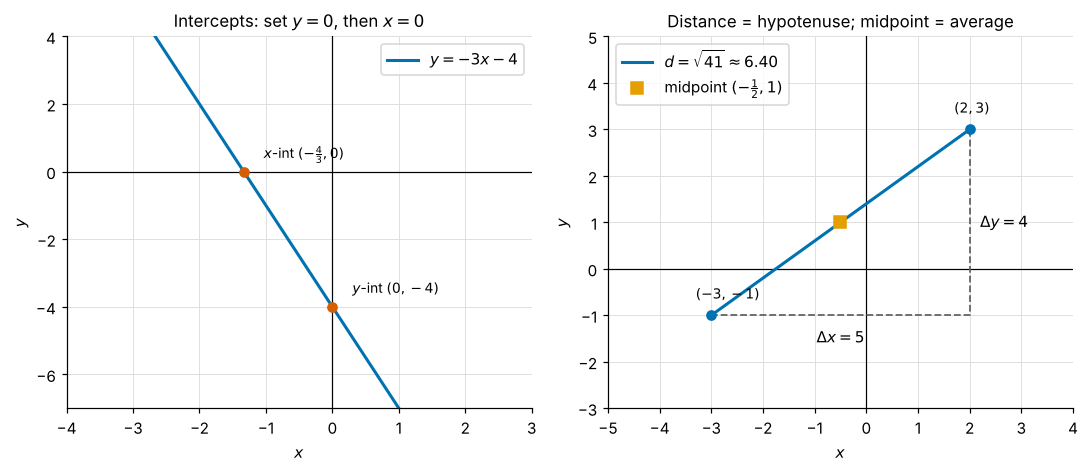

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.4))

# Left: y = -3x - 4 drawn from its two intercepts
ax = axs[0]
axes_through_origin(ax, (-4, 3), (-7, 4))
x = np.linspace(-4, 3, 100)
ax.plot(x, -3 * x - 4, color=C["blue"], lw=2, label="$y = -3x - 4$")
for (px, py), txt in [((-4/3, 0), r"$x$-int $(-\frac{4}{3}, 0)$"), ((0, -4), r"$y$-int $(0, -4)$")]:
    ax.plot(px, py, "o", color=C["red"], zorder=3)
    label(ax, px, py, txt, dx=0.3, dy=0.4)
ax.set_title("Intercepts: set $y=0$, then $x=0$")
ax.legend(loc="upper right")

# Right: distance and midpoint for (-3, -1) and (2, 3)
ax = axs[1]
axes_through_origin(ax, (-5, 4), (-3, 5))
P, Q = np.array([-3, -1]), np.array([2, 3])
M = (P + Q) / 2
ax.plot([P[0], Q[0]], [P[1], Q[1]], color=C["blue"], lw=2, label=r"$d=\sqrt{41}\approx 6.40$")
ax.plot([P[0], Q[0], Q[0]], [P[1], P[1], Q[1]], "--", color=C["gray"], lw=1.2)
ax.text(-0.5, -1.6, r"$\Delta x = 5$", ha="center")
ax.text(2.2, 1, r"$\Delta y = 4$", va="center")
for pt, txt in [(P, "$(-3,-1)$"), (Q, "$(2,3)$")]:
    ax.plot(*pt, "o", color=C["blue"], zorder=3)
    label(ax, *pt, txt, dx=-0.3, dy=0.35)
ax.plot(*M, "s", color=C["orange"], ms=8, zorder=3, label=r"midpoint $(-\frac{1}{2}, 1)$")
ax.set_title("Distance = hypotenuse; midpoint = average")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Sign errors with negatives: $2 - (-3) = 5$, not $-1$. Put every substituted value in parentheses.
- Dropping the square root at the end. $d^2 = 41$ is not the distance.
- Subtracting in the midpoint formula. It is a sum divided by 2.
- Intercepts are **points**. "The $y$-intercept is $-4$" is fine in conversation, but the coordinate pair is $(0, -4)$.
- Confusing street distance with straight-line distance. On a grid, driving east then north covers $|\Delta x| + |\Delta y|$; the distance formula gives the shorter diagonal, "as the crow flies."
:::

:::{tip} Where this shows up
The distance formula is the Euclidean ($L^2$) norm $\lVert \mathbf{p} - \mathbf{q} \rVert$, used for nearest-neighbor distances in spatial statistics, $k$-means clustering, and distances between points in a projected (e.g., UTM) coordinate system. Grid driving distance is the $L^1$ or "Manhattan" norm.
:::

(sec-2-2)=
## 2.2 Linear Equations in One Variable

### Three kinds of equations

| Type | Behavior | Example | Solution set |
|---|---|---|---|
| Identity | True for every $x$ | $3x = 2x + x$ | $\mathbb{R}$ |
| Conditional | True for some $x$ | $5x + 2 = 3x - 6$ | $\{-4\}$ |
| Inconsistent | Never true | $5x - 15 = 5(x - 4)$ | $\varnothing$ |

You can tell which kind you have when the variable cancels: a true statement ($0 = 0$) means identity, a false one ($-15 = -20$) means inconsistent.

### Solving

A linear equation can be written $ax + b = 0$ with $a \neq 0$. To solve: distribute, clear fractions by multiplying by the LCD, collect $x$ terms on one side, and divide by the coefficient. Whatever you do to one side, do to the other, and never divide by zero.

### Rational equations

A **rational equation** has the variable in at least one denominator.

1. Factor every denominator.
2. List the **excluded values** (anything making a denominator zero).
3. Multiply both sides by the LCD. No denominators should remain.
4. Solve, then throw out any solution that is an excluded value.

For a proportion $\dfrac{a}{b} = \dfrac{c}{d}$, cross-multiply: $ad = bc$.

**Worked example.** Solve $\dfrac{7}{2x} - \dfrac{5}{3x} = \dfrac{22}{3}$. Excluded: $x = 0$. The LCD is $6x$.

$$
6x\left(\frac{7}{2x}\right) - 6x\left(\frac{5}{3x}\right) = 6x\left(\frac{22}{3}\right)
\;\Rightarrow\; 21 - 10 = 44x
\;\Rightarrow\; x = \frac{1}{4}
$$

### Slope and forms of a line

$$
m = \frac{y_2 - y_1}{x_2 - x_1} = \frac{\text{rise}}{\text{run}}
$$

Either point can be "point 1," as long as you use the same order on top and bottom.

| Form | Equation | Good for |
|---|---|---|
| Slope-intercept | $y = mx + b$ | Reading slope and $y$-intercept $(0, b)$ |
| Point-slope | $y - y_1 = m(x - x_1)$ | Building a line from a slope and a point |
| Standard | $Ax + By = C$, with $A, B, C$ integers | Clean final answers, intercepts |
| Horizontal | $y = c$ | Slope $0$ |
| Vertical | $x = c$ | Slope **undefined** |

To find a line through two points: compute $m$, plug $m$ and either point into point-slope, then simplify.

### Parallel and perpendicular lines

- **Parallel:** same slope, different $y$-intercepts. (Same slope *and* same intercept means the same line.)
- **Perpendicular:** slopes are **negative reciprocals**, so $m_1 \cdot m_2 = -1$. The exception is a horizontal line paired with a vertical one.

**Worked example.** Find the line perpendicular to $5x - 3y + 4 = 0$ through $(-4, 1)$.

$$
\begin{aligned}
-3y = -5x - 4 \;&\Rightarrow\; y = \tfrac{5}{3}x + \tfrac{4}{3}, \quad m = \tfrac{5}{3}, \quad m_\perp = -\tfrac{3}{5} \\
y - 1 &= -\tfrac{3}{5}(x + 4) \\
y &= -\tfrac{3}{5}x - \tfrac{12}{5} + \tfrac{5}{5} = -\tfrac{3}{5}x - \tfrac{7}{5}
\end{aligned}
$$

**Graphically.** Parallel lines never meet; perpendicular lines meet at a right angle; and the "solution" of a rational equation can land exactly on a hole in the graph.

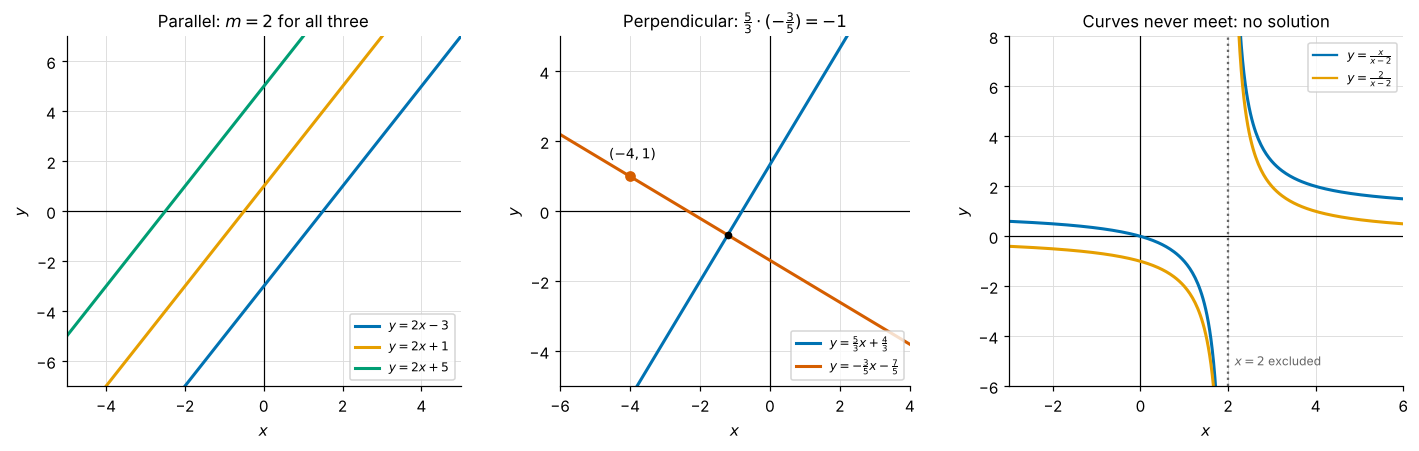

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
x = np.linspace(-6, 6, 400)

# Parallel: same slope, different intercepts
ax = axs[0]
axes_through_origin(ax, (-5, 5), (-7, 7))
for b, col in [(-3, C["blue"]), (1, C["orange"]), (5, C["green"])]:
    ax.plot(x, 2 * x + b, color=col, lw=2, label=f"$y = 2x {b:+d}$")
ax.set_title("Parallel: $m = 2$ for all three")
ax.legend(loc="lower right", fontsize=8)

# Perpendicular: worked example through (-4, 1)
ax = axs[1]
axes_through_origin(ax, (-6, 4), (-5, 5))
ax.set_aspect("equal")  # equal scale so the right angle LOOKS right
ax.plot(x, 5/3 * x + 4/3, color=C["blue"], lw=2, label=r"$y=\frac{5}{3}x+\frac{4}{3}$")
ax.plot(x, -3/5 * x - 7/5, color=C["red"], lw=2, label=r"$y=-\frac{3}{5}x-\frac{7}{5}$")
ax.plot(-4, 1, "o", color=C["red"], zorder=3); label(ax, -4, 1, "$(-4,1)$", dx=-0.6, dy=0.5)
xi = (-7/5 - 4/3) / (5/3 + 3/5); ax.plot(xi, 5/3 * xi + 4/3, "o", color="black", ms=4)
ax.set_title(r"Perpendicular: $\frac{5}{3}\cdot(-\frac{3}{5}) = -1$")
ax.legend(loc="lower right", fontsize=8)

# Rational equation with no solution: x/(x-2) = 2/(x-2)
ax = axs[2]
axes_through_origin(ax, (-3, 6), (-6, 8))
for side in (x[x < 1.97], x[x > 2.03]):
    ax.plot(side, side / (side - 2), color=C["blue"], lw=2)
    ax.plot(side, 2 / (side - 2), color=C["orange"], lw=2)
ax.plot([], [], color=C["blue"], label=r"$y=\frac{x}{x-2}$")
ax.plot([], [], color=C["orange"], label=r"$y=\frac{2}{x-2}$")
ax.axvline(2, ls=":", color=C["gray"])
ax.text(2.15, -5.2, "$x = 2$ excluded", fontsize=8, color=C["gray"])
ax.set_title("Curves never meet: no solution")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Not checking excluded values. $\dfrac{x}{x - 2} = \dfrac{2}{x - 2}$ "solves" to $x = 2$, which is excluded, so there is **no solution**.
- Mixing the order in the slope formula: $\dfrac{y_2 - y_1}{x_1 - x_2}$ flips the sign.
- For a perpendicular slope, flipping the fraction **and** changing the sign. The perpendicular to $m = 2$ is $-\tfrac{1}{2}$, not $\tfrac{1}{2}$ or $-2$.
- Zero slope (horizontal, $y = c$) and undefined slope (vertical, $x = c$) are different things.
- Treating a binomial denominator as separable. In $\dfrac{1}{x}$ and $\dfrac{1}{x - 1}$, the $x$ in $x - 1$ is not a shared factor.
:::

:::{tip} Where this shows up
Simple linear regression is $y = \beta_0 + \beta_1 x$, and the least-squares line always passes through $(\bar{x}, \bar{y})$, so it can be written in point-slope form as $y - \bar{y} = \hat{\beta}_1 (x - \bar{x})$. In Stewart, the tangent line at $x = a$ is point-slope with $m = f'(a)$: $y - f(a) = f'(a)(x - a)$.
:::

(sec-2-3)=
## 2.3 Models and Applications

### Setting up a model

1. Identify the known quantities.
2. Assign **one** variable to an unknown.
3. Write every other unknown in terms of that variable.
4. Translate the words into an equation ("is" usually means $=$).
5. Solve, then answer the actual question in words, with units.

| Verbal | Math |
|---|---|
| One number exceeds another by $a$ | $x,\ x + a$ |
| One number is $a$ less than twice another | $x,\ 2x - a$ |
| The product of a number and $a$, decreased by $b$ | $ax - b$ |
| The rest of a total $T$ after $x$ | $T - x$ |

### Linear cost models

A model of the form $C = (\text{rate})\,x + (\text{fixed cost})$ has a **variable cost** that scales with $x$ and a **fixed cost** that doesn't. To find where two plans cost the same, set the models equal.

**Worked example.** Plan A: $A = 0.05x + 34$. Plan B: $B = 0.04x + 40$.

$$
0.05x + 34 = 0.04x + 40 \;\Rightarrow\; 0.01x = 6 \;\Rightarrow\; x = 600 \text{ minutes}
$$

Below 600 minutes, A (the lower fixed fee) is cheaper. Above 600, B (the lower rate) is cheaper.

### Formulas worth knowing

| Situation | Formula |
|---|---|
| Distance | $d = rt$ |
| Rectangle | $P = 2L + 2W$, $\ A = LW$ |
| Box | $V = LWH$ |
| Simple interest | $I = Prt$ |
| Triangle | $A = \tfrac{1}{2}bh$ |
| Cylinder | $V = \pi r^2 h$ |

You can also rearrange a formula to solve for any one variable, e.g. $P = 2L + 2W \Rightarrow W = \dfrac{P - 2L}{2}$.

**Worked example (rate).** Andrew's 30-minute drive to work is at rate $r$; the 40-minute drive home is at $r - 10$. The distance is the same, and minutes become hours.

$$
r\left(\tfrac{1}{2}\right) = (r - 10)\left(\tfrac{2}{3}\right)
\;\xrightarrow{\times 6}\; 3r = 4r - 40
\;\Rightarrow\; r = 40, \quad d = 40 \cdot \tfrac{1}{2} = 20 \text{ mi}
$$

**Worked example (mixture).** How much 30% and 70% salt solution make 20 qt of 40% solution? Let $x$ be the quarts of 30%; then $20 - x$ is the 70%. Track the salt itself:

$$
0.30x + 0.70(20 - x) = 0.40(20)
\;\Rightarrow\; -0.40x + 14 = 8
\;\Rightarrow\; x = 15
$$

So 15 qt of 30% and 5 qt of 70%.

**Graphically.** An equal-cost question is asking where two lines cross. Each plan wins on one side of the crossing.

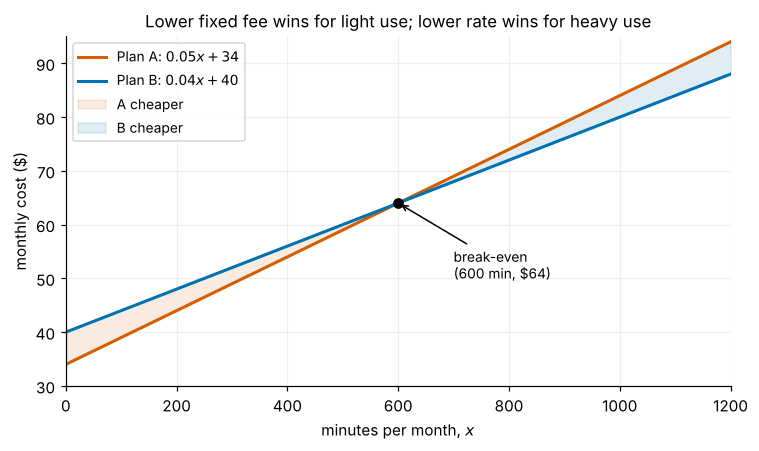

In [4]:
m = np.linspace(0, 1200, 200)
A, B = 0.05 * m + 34, 0.04 * m + 40

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(m, A, color=C["red"], lw=2, label="Plan A: $0.05x + 34$")
ax.plot(m, B, color=C["blue"], lw=2, label="Plan B: $0.04x + 40$")
ax.fill_between(m, A, B, where=A < B, color=C["red"], alpha=0.12, label="A cheaper")
ax.fill_between(m, A, B, where=A > B, color=C["blue"], alpha=0.12, label="B cheaper")
ax.plot(600, 64, "o", color="black", zorder=3)
ax.annotate("break-even\n(600 min, \\$64)", (600, 64), xytext=(700, 50),
            arrowprops=dict(arrowstyle="->", color="black"), fontsize=9)
ax.set_xlabel("minutes per month, $x$"); ax.set_ylabel("monthly cost (\\$)")
ax.set_xlim(0, 1200); ax.set_ylim(30, 95)
ax.grid(True, color="#eeeeee")
ax.set_title("Lower fixed fee wins for light use; lower rate wins for heavy use")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Mixing units: a rate in mi/h needs time in hours. 40 minutes is $\tfrac{2}{3}$ h, not $40$ or $0.4$.
- Using two variables for two unknowns that are linked. Write the second one in terms of the first.
- Stopping at $r = 40$ when the question asked for the distance.
- Using percents as whole numbers: 7% is $0.07$.
- In mixtures, adding concentrations instead of the amounts of the substance.
:::

:::{tip} Where this shows up
A mixture problem is a weighted average: $0.40 = w(0.30) + (1 - w)(0.70)$ with $w = 0.75$. Expected value, finite mixture models, and pooled estimates all have this structure. Equal-cost problems are a first look at finding where two functions intersect.
:::

(sec-2-4)=
## 2.4 Complex Numbers

### Definitions

$$
i = \sqrt{-1}, \qquad i^2 = -1
$$

- For $a > 0$: $\sqrt{-a} = i\sqrt{a}$. So $\sqrt{-49} = 7i$ and $\sqrt{-24} = 2i\sqrt{6}$.
- A **complex number** in standard form is $a + bi$, where $a$ is the **real part** and $b$ is the **imaginary part**. Note that $b$ itself is a real number.
- If $b = 0$, the number is real. If $a = 0$ and $b \neq 0$, it is **pure imaginary**.
- The **complex plane** plots $a + bi$ as the point $(a, b)$: real axis horizontal, imaginary axis vertical.

### Operations

| Operation | Method |
|---|---|
| Add / subtract | Combine real parts and imaginary parts separately: $(a + bi) \pm (c + di) = (a \pm c) + (b \pm d)i$ |
| Multiply | FOIL, then replace $i^2$ with $-1$: $(a + bi)(c + di) = (ac - bd) + (ad + bc)i$ |
| Divide | Multiply the top and bottom by the **conjugate** of the denominator |

The **complex conjugate** of $a + bi$ is $a - bi$. A number times its conjugate is real and nonnegative:

$$
(a + bi)(a - bi) = a^2 + b^2
$$

**Worked example.** Divide $2 + 5i$ by $4 - i$.

$$
\frac{2 + 5i}{4 - i} \cdot \frac{4 + i}{4 + i}
= \frac{8 + 2i + 20i + 5i^2}{16 + 1}
= \frac{3 + 22i}{17}
= \frac{3}{17} + \frac{22}{17}i
$$

### Powers of $i$

The powers repeat every four: $i^1 = i,\ i^2 = -1,\ i^3 = -i,\ i^4 = 1$. Divide the exponent by 4 and use the remainder.

$$
i^{35} = i^{4 \cdot 8 + 3} = (i^4)^8 \cdot i^3 = -i
$$

**Graphically.** A complex number is a point (or arrow) in the plane. Conjugates are mirror images across the real axis, and each multiplication by $i$ is a quarter-turn, which is why the powers of $i$ cycle every four.

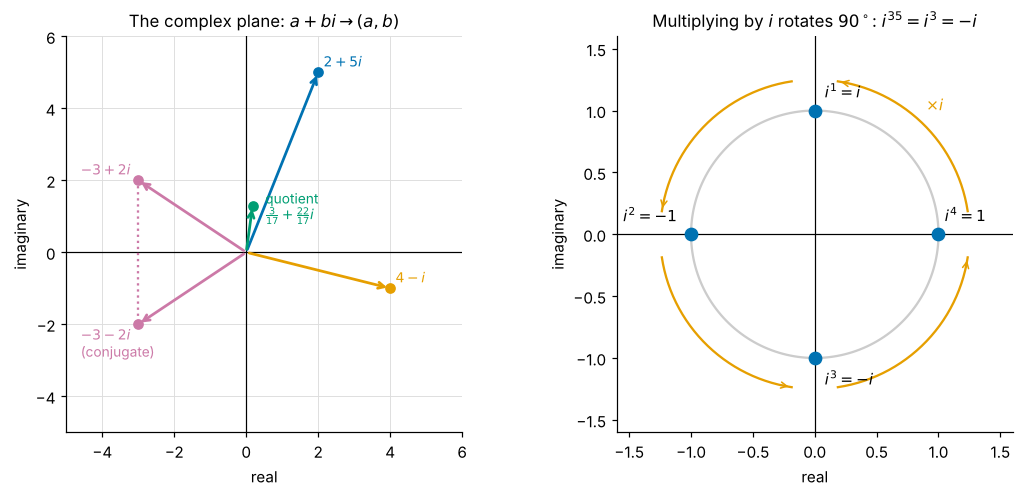

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4.6))

def arrow(ax, z, col, txt, dx=0.15, dy=0.15):
    ax.annotate("", (z.real, z.imag), (0, 0), arrowprops=dict(arrowstyle="->", color=col, lw=1.8))
    ax.plot(z.real, z.imag, "o", color=col)
    ax.text(z.real + dx, z.imag + dy, txt, color=col, fontsize=9)

# Left: numbers from the worked examples, plus a conjugate pair
ax = axs[0]
axes_through_origin(ax, (-5, 6), (-5, 6))
ax.set_aspect("equal"); ax.set_xlabel("real"); ax.set_ylabel("imaginary")
arrow(ax, 2 + 5j, C["blue"], "$2+5i$")
arrow(ax, 4 - 1j, C["orange"], "$4-i$")
arrow(ax, (2 + 5j) / (4 - 1j), C["green"], "quotient\n" + r"$\frac{3}{17}+\frac{22}{17}i$", dx=0.35, dy=-0.4)
arrow(ax, -3 + 2j, C["purple"], "$-3+2i$", dx=-1.6)
arrow(ax, -3 - 2j, C["purple"], "$-3-2i$\n(conjugate)", dx=-1.6, dy=-0.9)
ax.plot([-3, -3], [2, -2], ":", color=C["purple"])
ax.set_title("The complex plane: $a + bi \\to (a, b)$")

# Right: powers of i as quarter turns
ax = axs[1]
axes_through_origin(ax, (-1.6, 1.6), (-1.6, 1.6), grid=False)
ax.set_aspect("equal"); ax.set_xlabel("real"); ax.set_ylabel("imaginary")
t = np.linspace(0, 2 * np.pi, 200)
ax.plot(np.cos(t), np.sin(t), color="#cccccc")
pts = {r"$i^1=i$": (0, 1), r"$i^2=-1$": (-1, 0), r"$i^3=-i$": (0, -1), r"$i^4=1$": (1, 0)}
offs = [(0.08, 0.1), (-0.55, 0.1), (0.08, -0.22), (0.05, 0.1)]
for (txt, (a, b)), (dx, dy) in zip(pts.items(), offs):
    ax.plot(a, b, "o", color=C["blue"], ms=8); ax.text(a + dx, b + dy, txt, fontsize=10)
for k in range(4):
    a0, a1 = k * np.pi / 2 + 0.15, (k + 1) * np.pi / 2 - 0.15
    s = np.linspace(a0, a1, 30)
    ax.plot(1.25 * np.cos(s), 1.25 * np.sin(s), color=C["orange"])
    ax.annotate("", (1.25 * np.cos(a1), 1.25 * np.sin(a1)), (1.25 * np.cos(s[-3]), 1.25 * np.sin(s[-3])),
                arrowprops=dict(arrowstyle="->", color=C["orange"]))
ax.text(0.9, 1.0, r"$\times i$", color=C["orange"])
ax.set_title(r"Multiplying by $i$ rotates $90^\circ$: $i^{35} = i^{3} = -i$")
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- $\sqrt{-4}\cdot\sqrt{-9} \neq \sqrt{36} = 6$. Convert to $i$ first: $(2i)(3i) = 6i^2 = -6$. The product rule for radicals needs nonnegative radicands.
- Forgetting that $i^2 = -1$ turns a $+bd$ term into $-bd$.
- The conjugate flips only the sign of the imaginary part: the conjugate of $-3 + 2i$ is $-3 - 2i$, not $3 - 2i$.
- The imaginary part of $3 - 4i$ is $-4$, not $-4i$.
- Leaving an $i$ in the denominator. Standard form has a real denominator.
:::

:::{tip} Where this shows up
Complex roots appear whenever a quadratic has a negative discriminant (§2.5), and they come in conjugate pairs. In linear algebra, a rotation matrix has complex eigenvalues. In time-series analysis, complex characteristic roots of an AR process produce cycles, and spectral (Fourier) methods are built on $e^{i\theta} = \cos\theta + i\sin\theta$.
:::

(sec-2-5)=
## 2.5 Quadratic Equations

A **quadratic equation** in standard form is $ax^2 + bx + c = 0$ with $a \neq 0$.

### Choosing a method

| Method | Use when | Key idea |
|---|---|---|
| Factoring | It factors nicely | **Zero-product property**: if $ab = 0$, then $a = 0$ or $b = 0$ |
| Square root property | No $x$ term, or a perfect square $(x + h)^2 = k$ | $x^2 = k \Rightarrow x = \pm\sqrt{k}$ |
| Completing the square | It doesn't factor and you want to see the structure | Build a perfect square trinomial |
| Quadratic formula | Always works | $x = \dfrac{-b \pm \sqrt{b^2 - 4ac}}{2a}$ |

### Factoring

Get **zero on one side**, factor (GCF first, then the methods from §1.5), and set each factor to zero.

**Worked example.** Solve $4x^2 + 15x + 9 = 0$. Here $ac = 36$, and $3 \cdot 12 = 36$ with $3 + 12 = 15$.

$$
4x^2 + 3x + 12x + 9 = x(4x + 3) + 3(4x + 3) = (x + 3)(4x + 3) = 0
\;\Rightarrow\; x = -3,\ -\tfrac{3}{4}
$$

The solutions are the $x$-intercepts of $y = 4x^2 + 15x + 9$.

### Completing the square

1. If $a \neq 1$, divide everything by $a$.
2. Move the constant to the right side.
3. Add $\left(\tfrac{b}{2}\right)^2$ to **both** sides.
4. Factor the left side as $\left(x + \tfrac{b}{2}\right)^2$ and use the square root property.

**Worked example.** Solve $x^2 + 4x + 1 = 0$.

$$
x^2 + 4x = -1 \;\Rightarrow\; x^2 + 4x + 4 = 3 \;\Rightarrow\; (x + 2)^2 = 3 \;\Rightarrow\; x = -2 \pm \sqrt{3}
$$

Doing these same steps to $ax^2 + bx + c = 0$ in general produces the quadratic formula.

### The quadratic formula and discriminant

$$
x = \frac{-b \pm \sqrt{b^2 - 4ac}}{2a}
$$

The **discriminant** $b^2 - 4ac$ tells you what kind of solutions to expect (for integer coefficients):

| Discriminant | Solutions |
|---|---|
| $= 0$ | One rational (double) solution |
| $> 0$, perfect square | Two rational |
| $> 0$, not a perfect square | Two irrational |
| $< 0$ | Two complex (conjugates) |

**Worked example.** Solve $x^2 + x + 2 = 0$. Here $b^2 - 4ac = 1 - 8 = -7$.

$$
x = \frac{-1 \pm \sqrt{-7}}{2} = -\frac{1}{2} \pm \frac{\sqrt{7}}{2}\,i
$$

### Pythagorean theorem

For a right triangle with legs $a, b$ and hypotenuse $c$: $a^2 + b^2 = c^2$. Solving for a missing side is a quadratic; keep only the positive root, since it's a length.

**Worked example.** Hypotenuse 12, one leg 4: $a^2 = 144 - 16 = 128$, so $a = \sqrt{128} = 8\sqrt{2}$.

**Graphically.** Real solutions of $ax^2 + bx + c = 0$ are the $x$-intercepts of $y = ax^2 + bx + c$. The sign of the discriminant decides whether the parabola crosses the axis twice, touches it once, or misses it (complex solutions).

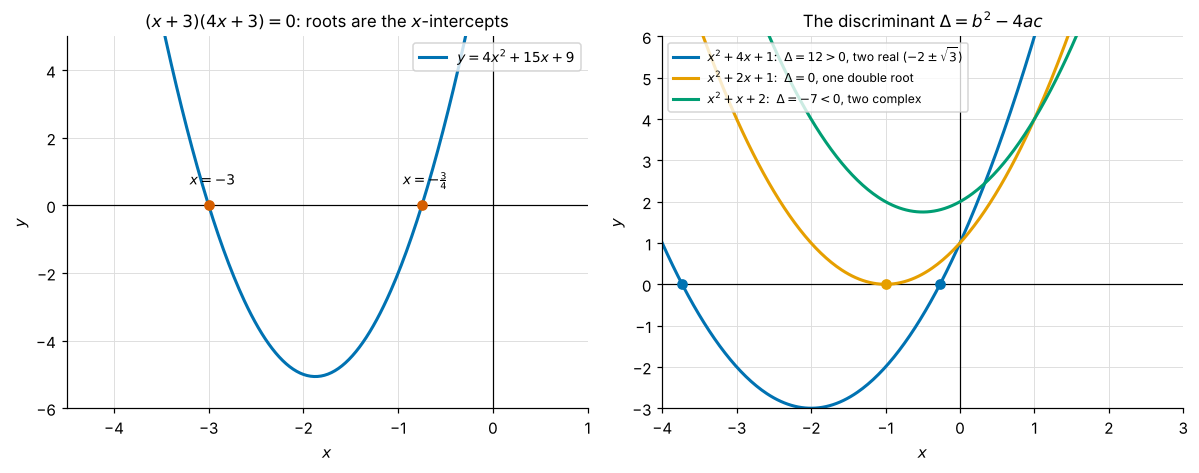

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))

# Left: factoring worked example
ax = axs[0]
axes_through_origin(ax, (-4.5, 1), (-6, 5))
x = np.linspace(-4.5, 1, 300)
ax.plot(x, 4 * x**2 + 15 * x + 9, color=C["blue"], lw=2, label="$y = 4x^2 + 15x + 9$")
for r, txt in [(-3, "$x=-3$"), (-0.75, r"$x=-\frac{3}{4}$")]:
    ax.plot(r, 0, "o", color=C["red"], zorder=3); label(ax, r, 0, txt, dx=-0.2, dy=0.6)
ax.set_title("$(x+3)(4x+3)=0$: roots are the $x$-intercepts")
ax.legend(loc="upper right", fontsize=9)

# Right: three discriminant cases
ax = axs[1]
axes_through_origin(ax, (-4, 3), (-3, 6))
x = np.linspace(-4, 3, 300)
cases = [
    (x**2 + 4 * x + 1, C["blue"],   r"$x^2+4x+1$:  $\Delta=12>0$, two real ($-2\pm\sqrt{3}$)"),
    (x**2 + 2 * x + 1, C["orange"], r"$x^2+2x+1$:  $\Delta=0$, one double root"),
    (x**2 + x + 2,     C["green"],  r"$x^2+x+2$:  $\Delta=-7<0$, two complex"),
]
for y, col, txt in cases:
    ax.plot(x, y, color=col, lw=2, label=txt)
for r in (-2 - 3**0.5, -2 + 3**0.5):
    ax.plot(r, 0, "o", color=C["blue"], zorder=3)
ax.plot(-1, 0, "o", color=C["orange"], zorder=3)
ax.set_title(r"The discriminant $\Delta = b^2 - 4ac$")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Factoring without zero on one side. From $x(x - 1) = 6$ you **cannot** conclude $x = 6$ or $x - 1 = 6$. Rewrite as $x^2 - x - 6 = 0 = (x - 3)(x + 2)$.
- Dividing by $x$ and losing a solution: from $3x^2 = 12x$, dividing by $x$ gives only $x = 4$. Factoring $3x(x - 4) = 0$ gives $x = 0$ as well.
- Forgetting the $\pm$ when taking a square root.
- Completing the square with $a \neq 1$ without dividing by $a$ first.
- In the quadratic formula: $-b$ when $b$ is negative ($-(-5) = 5$), and $2a$ divides the **entire** numerator, not just the radical.
:::

:::{tip} Where this shows up
Completing the square is how you recognize a normal density inside a messier expression. It is the core algebra of the normal–normal conjugate update for a posterior mean and variance, and it shows up in the vertex form $a(x - h)^2 + k$ for finding the minimum of a squared-error loss.
:::

(sec-2-6)=
## 2.6 Other Types of Equations

### Rational exponents

Recall $x^{m/n} = \left(\sqrt[n]{x}\right)^m$. To solve $x^{m/n} = k$, raise both sides to the reciprocal power $n/m$.

$$
x^{5/4} = 32 \;\Rightarrow\; x = 32^{4/5} = \left(\sqrt[5]{32}\right)^4 = 2^4 = 16
$$

When the numerator $m$ is **even**, check for a $\pm$: $x^{2/3} = 4$ means $\left(\sqrt[3]{x}\right)^2 = 4$, so $\sqrt[3]{x} = \pm 2$ and $x = \pm 8$.

When several rational exponents appear, set the equation to zero and factor out the **lowest** power (as in §1.5).

**Worked example.** Solve $3x^{3/4} = x^{1/2}$.

$$
3x^{3/4} - x^{2/4} = 0 \;\Rightarrow\; x^{1/2}\left(3x^{1/4} - 1\right) = 0
\;\Rightarrow\; x = 0 \ \text{ or } \ x^{1/4} = \tfrac{1}{3} \Rightarrow x = \tfrac{1}{81}
$$

### Polynomial equations

Set to zero, pull out the GCF, then factor (grouping works when there are four terms). A degree-$n$ polynomial equation has $n$ solutions counting complex and repeated ones.

$$
x^3 + x^2 - 9x - 9 = x^2(x + 1) - 9(x + 1) = (x - 3)(x + 3)(x + 1) = 0 \;\Rightarrow\; x = 3, -3, -1
$$

At a **double solution** (like $x = 0$ in $5x^2(x^2 - 16) = 0$), the graph touches the $x$-axis and bounces back instead of crossing.

### Radical equations

1. Isolate the radical.
2. Raise both sides to the index ($n$th root → $n$th power).
3. Solve. If a radical remains, repeat.
4. **Check every candidate in the original equation.** Raising to an even power can create **extraneous solutions**.

**Worked example.** Solve $\sqrt{x + 3} = 3x - 1$.

$$
x + 3 = 9x^2 - 6x + 1 \;\Rightarrow\; 9x^2 - 7x - 2 = 0 \;\Rightarrow\; (9x + 2)(x - 1) = 0
$$

Check: $x = 1$ gives $2 = 2$ ✓. $x = -\tfrac{2}{9}$ gives $\sqrt{25/9} = \tfrac{5}{3}$ on the left but $-\tfrac{5}{3}$ on the right ✗. The only solution is $x = 1$.

### Absolute value equations

Isolate the absolute value first. Then for $|A| = B$:

- $B > 0$: two equations, $A = B$ or $A = -B$.
- $B = 0$: one equation, $A = 0$.
- $B < 0$: no solution.

$$
|2x - 1| - 4 = 3 \;\Rightarrow\; |2x - 1| = 7 \;\Rightarrow\; 2x - 1 = \pm 7 \;\Rightarrow\; x = 4,\ -3
$$

### Equations in quadratic form

If the leading exponent is **twice** the middle exponent, substitute $u$ for the middle term's variable part, solve the quadratic in $u$, then substitute back.

**Worked example.** Solve $x^4 - 4x^2 - 45 = 0$. Let $u = x^2$.

$$
u^2 - 4u - 45 = (u - 9)(u + 5) = 0
\;\Rightarrow\; x^2 = 9 \text{ or } x^2 = -5
\;\Rightarrow\; x = \pm 3,\ \pm i\sqrt{5}
$$

The same trick handles a binomial: in $(x + 2)^2 + 11(x + 2) - 12 = 0$, let $u = x + 2$.

**Graphically.** Squaring both sides of $\sqrt{x+3} = 3x - 1$ also captures $-\sqrt{x+3} = 3x - 1$, the reflection of the radical curve. That reflected branch is where the extraneous solution comes from. On the right, single roots cross the axis and a double root bounces.

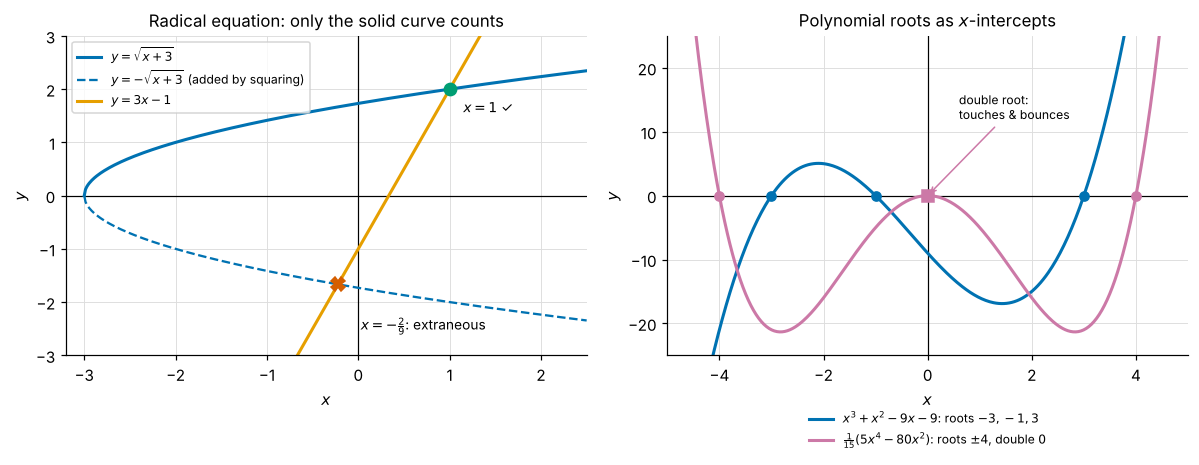

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))

# Left: where the extraneous root comes from
ax = axs[0]
axes_through_origin(ax, (-3.2, 2.5), (-3, 3))
x = np.linspace(-3, 2.5, 400)
ax.plot(x, np.sqrt(x + 3), color=C["blue"], lw=2, label=r"$y=\sqrt{x+3}$")
ax.plot(x, -np.sqrt(x + 3), color=C["blue"], lw=1.5, ls="--", label=r"$y=-\sqrt{x+3}$ (added by squaring)")
ax.plot(x, 3 * x - 1, color=C["orange"], lw=2, label="$y=3x-1$")
ax.plot(1, 2, "o", color=C["green"], ms=8, zorder=3); label(ax, 1, 2, r"$x=1$ ✓", dx=0.15, dy=-0.45)
ax.plot(-2/9, -5/3, "X", color=C["red"], ms=9, zorder=3)
label(ax, -2/9, -5/3, r"$x=-\frac{2}{9}$: extraneous", dx=0.25, dy=-0.85)
ax.set_title("Radical equation: only the solid curve counts")
ax.legend(loc="upper left", fontsize=8)

# Right: crossing vs bouncing
ax = axs[1]
axes_through_origin(ax, (-5, 5), (-25, 25))
x = np.linspace(-5, 5, 400)
ax.plot(x, x**3 + x**2 - 9 * x - 9, color=C["blue"], lw=2, label="$x^3+x^2-9x-9$: roots $-3,-1,3$")
ax.plot(x, (5 * x**4 - 80 * x**2) / 15, color=C["purple"], lw=2,
        label=r"$\frac{1}{15}(5x^4-80x^2)$: roots $\pm4$, double $0$")
for r in (-3, -1, 3):
    ax.plot(r, 0, "o", color=C["blue"], zorder=3)
for r in (-4, 4):
    ax.plot(r, 0, "o", color=C["purple"], zorder=3)
ax.plot(0, 0, "s", color=C["purple"], ms=8, zorder=3)
ax.annotate("double root:\ntouches & bounces", (0, 0), xytext=(0.6, 12), fontsize=8,
            arrowprops=dict(arrowstyle="->", color=C["purple"]))
ax.set_title("Polynomial roots as $x$-intercepts")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), fontsize=8, ncol=1, frameon=False)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Squaring before isolating the radical. $\sqrt{x} + 2 = x$ must become $\sqrt{x} = x - 2$ first.
- Squaring a binomial side as if it were two squares: $(x - 2)^2 = x^2 - 4x + 4$, not $x^2 + 4$.
- Skipping the check. Extraneous solutions don't come from an algebra error, so careful work won't catch them; only substitution will.
- Writing $|x| = -3 \Rightarrow x = \pm 3$. An absolute value is never negative, so there is no solution.
- With $u$-substitution, stopping at the values of $u$.
:::

:::{tip} Where this shows up
Substituting $u$ for a repeated piece is exactly $u$-substitution for integrals in Stewart. Checking candidate solutions against the original equation is the same habit as checking critical points against a function's domain, or checking that an estimate respects its constraints (a variance can't be negative).
:::

(sec-2-7)=
## 2.7 Linear Inequalities and Absolute Value Inequalities

### Interval notation

Parentheses mean the endpoint is **excluded**; brackets mean it is **included**. Infinity always gets a parenthesis.

| Inequality | Interval |
|---|---|
| $a < x < b$ | $(a, b)$ |
| $a \le x \le b$ | $[a, b]$ |
| $a \le x < b$ | $[a, b)$ |
| $x > a$ | $(a, \infty)$ |
| $x \le b$ | $(-\infty, b]$ |
| $x < a$ or $x > b$ | $(-\infty, a) \cup (b, \infty)$ |
| All reals | $(-\infty, \infty)$ |

Set-builder notation says the same thing in words: $\{x \mid x \ge 4\}$ is $[4, \infty)$.

### Properties of inequalities

- Adding or subtracting the same number on both sides keeps the direction.
- Multiplying or dividing by a **positive** number keeps the direction.
- Multiplying or dividing by a **negative** number **reverses** the direction.

**Worked example.** $4(x + 3) \ge 6x + 10 \Rightarrow 4x + 12 \ge 6x + 10 \Rightarrow -2x \ge -2 \Rightarrow x \le 1$, or $(-\infty, 1]$.

### Compound inequalities

Solve all three parts at once, doing the same operation to every part.

$$
3 \le 2x + 2 < 6 \;\Rightarrow\; 1 \le 2x < 4 \;\Rightarrow\; \tfrac{1}{2} \le x < 2 \;\Rightarrow\; \left[\tfrac{1}{2}, 2\right)
$$

If the variable appears in all three parts, split it into two inequalities joined by "and," solve each, and intersect the results.

### Absolute value inequalities

$|x - a|$ is the **distance** between $x$ and $a$. For $k > 0$:

| Inequality | Meaning | Equivalent | Shape |
|---|---|---|---|
| $\lvert X \rvert < k$ | within $k$ of 0 | $-k < X < k$ | One interval ("and") |
| $\lvert X \rvert > k$ | farther than $k$ from 0 | $X < -k$ or $X > k$ | Two pieces ("or") |

The same holds with $\le$ and $\ge$. "All $x$ within 4 of 5" is $|x - 5| \le 4$, which is $[1, 9]$.

**Worked example.** Find where $y = -\tfrac{1}{2}|4x - 5| + 3$ is negative. Isolate the absolute value, flipping when dividing by a negative:

$$
-\tfrac{1}{2}|4x - 5| < -3 \;\Rightarrow\; |4x - 5| > 6
\;\Rightarrow\; 4x - 5 < -6 \ \text{ or } \ 4x - 5 > 6
\;\Rightarrow\; \left(-\infty, -\tfrac{1}{4}\right) \cup \left(\tfrac{11}{4}, \infty\right)
$$

**Graphically.** $|x - a| \le k$ is a window of half-width $k$ around $a$; $|X| > k$ is everything outside a window. You can also read an inequality off a graph as the $x$-values where the curve is below the axis.

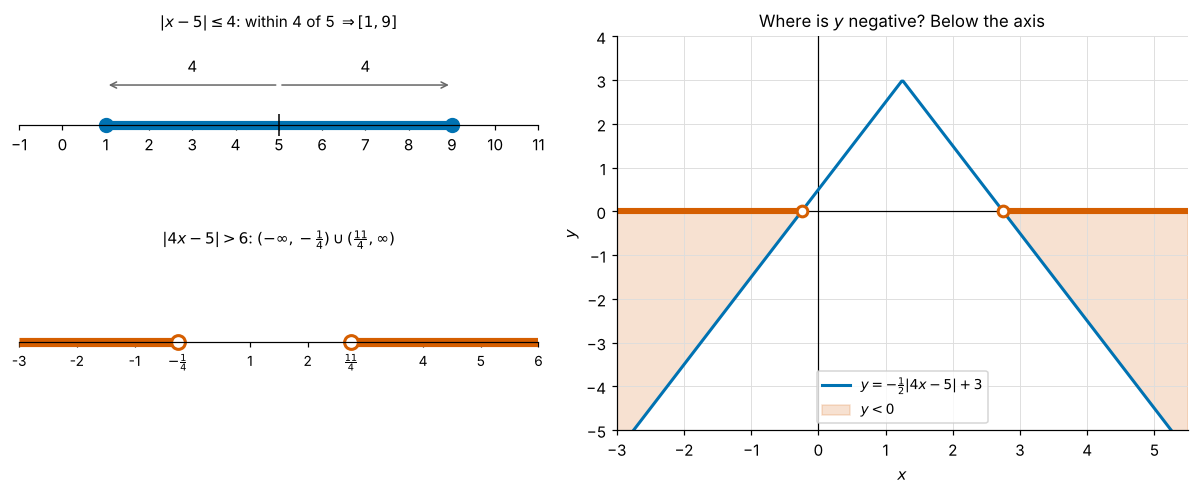

In [8]:
fig = plt.figure(figsize=(11, 4.6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.1])

def number_line(ax, lo, hi):
    ax.set_xlim(lo, hi); ax.set_ylim(-1, 1); ax.set_yticks([])
    for s in ("left", "right", "top"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_position("center")

# Top-left: |x - 5| <= 4  ->  [1, 9]
ax = fig.add_subplot(gs[0, 0]); number_line(ax, -1, 11)
ax.plot([1, 9], [0, 0], color=C["blue"], lw=6, solid_capstyle="butt")
ax.plot([1, 9], [0, 0], "o", color=C["blue"], ms=9)               # closed = included
ax.annotate("", (1, 0.45), (5, 0.45), arrowprops=dict(arrowstyle="->", color=C["gray"]))
ax.annotate("", (9, 0.45), (5, 0.45), arrowprops=dict(arrowstyle="->", color=C["gray"]))
ax.text(3, 0.6, "4", ha="center"); ax.text(7, 0.6, "4", ha="center")
ax.plot(5, 0, "|", color="black", ms=14)
ax.set_xticks(range(-1, 12))
ax.set_title(r"$|x-5|\leq 4$: within 4 of 5 $\Rightarrow [1, 9]$", fontsize=10)

# Bottom-left: |4x - 5| > 6  ->  two rays, open endpoints
ax = fig.add_subplot(gs[1, 0]); number_line(ax, -3, 6)
ax.plot([-3, -0.25], [0, 0], color=C["red"], lw=6, solid_capstyle="butt")
ax.plot([2.75, 6], [0, 0], color=C["red"], lw=6, solid_capstyle="butt")
for e in (-0.25, 2.75):
    ax.plot(e, 0, "o", ms=9, mfc="white", mec=C["red"], mew=2)   # open = excluded
ax.set_xticks([-3, -2, -1, -0.25, 1, 2, 2.75, 4, 5, 6])
ax.set_xticklabels(["-3", "-2", "-1", r"$-\frac{1}{4}$", "1", "2", r"$\frac{11}{4}$", "4", "5", "6"], fontsize=9)
ax.set_title(r"$|4x-5|>6$: $(-\infty,-\frac{1}{4})\cup(\frac{11}{4},\infty)$", fontsize=10)

# Right: reading the same answer off a graph
ax = fig.add_subplot(gs[:, 1])
axes_through_origin(ax, (-3, 5.5), (-5, 4))
x = np.linspace(-3, 5.5, 400)
y = -0.5 * np.abs(4 * x - 5) + 3
ax.plot(x, y, color=C["blue"], lw=2, label=r"$y=-\frac{1}{2}|4x-5|+3$")
ax.fill_between(x, y, 0, where=y < 0, color=C["red"], alpha=0.18, label="$y < 0$")
for e in (-0.25, 2.75):
    ax.plot(e, 0, "o", ms=7, mfc="white", mec=C["red"], mew=2, zorder=3)
ax.plot([-3, -0.25], [0, 0], color=C["red"], lw=4)
ax.plot([2.75, 5.5], [0, 0], color=C["red"], lw=4)
ax.set_title("Where is $y$ negative? Below the axis")
ax.legend(loc="lower center", fontsize=9)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Forgetting to flip the sign after multiplying or dividing by a negative. This includes the hidden case of dividing by a coefficient like $-2x$.
- Multiplying both sides by a variable whose sign you don't know.
- Writing $[4, \infty]$. Infinity is never included.
- Mixing up the shapes: "less than" absolute value gives one interval; "greater than" gives two. Never write $-\tfrac{1}{4} > x > \tfrac{11}{4}$, which describes nothing.
- Not isolating the absolute value before splitting it.
- Edge cases: $|X| < -2$ has no solution, but $|X| > -2$ is true for every $x$.
- Writing an interval backward. The smaller number always comes first: $\left(-4, \tfrac{5}{6}\right)$.
:::

:::{tip} Where this shows up
A confidence interval is an absolute value inequality: $|\bar{x} - \mu| \le E$ unpacks to $\bar{x} - E \le \mu \le \bar{x} + E$. The $\varepsilon$–$\delta$ definition of a limit in Stewart, and nearly every proof in Abbott, is phrased as "$|x - a| < \delta$ implies $|f(x) - L| < \varepsilon$."
:::